In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D,Activation, MaxPooling2D, UpSampling2D, Concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda, ReLU
from tensorflow.keras.applications import ResNet101
import numpy as np
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping,ReduceLROnPlateau
from tensorflow.keras.applications.resnet import preprocess_input
from tensorflow.keras.metrics import MeanIoU

In [4]:
# hiper parametros
height_img = 288
width_img = 288
canais = 3
epochs = 50
batch_size = 16
lr = 0.00001

In [ ]:
# carregand treino e validação
x_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_train.npy')
y_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_train.npy')
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy')

In [ ]:
def convolucao(input, filters):
  x = Conv2D(filters,3, padding='same')(input)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  x = Conv2D(filters,3, padding='same')(x)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  return x

In [ ]:
def decoder_resnet(inputs,skips, filters):
    x = Conv2DTranspose(filters, (2,2), strides=2, padding="same")(inputs)
    x = Concatenate()([x,skips])


    x = convolucao(x,filters)
    return x

In [ ]:
def resnet101_unet(input_shape):
    inputs = Input(input_shape)
    # camada de entrada da rede

    input = preprocess_input(inputs)
    # o resnet foi treinado em imagens RGB e por isso pegamos esse preprocess proprio do resnet


    resnet = ResNet101(include_top=False, weights="imagenet", input_tensor=input)
    # o resnet101 possui 101 camadas
    
    # skips conections 
    s1 = inputs
    # convolução com 512 filtros
    s2 = resnet.get_layer("conv1_relu").output
    s3 = resnet.get_layer("conv2_block3_out").output
    s4 = resnet.get_layer("conv3_block4_out").output

    # BASE DA ARQUITETURA
    b1 = resnet.get_layer("conv4_block23_out").output
    #b1 seria a base da arquitetura U-Net

    # subindo os filtros e diminuindo as saidas, recebe a camada anterior, a conexão de skip e o numero de filtros
    d1 = decoder_resnet(b1, s4, 512)
    d2 = decoder_resnet(d1, s3, 256)
    d3 = decoder_resnet(d2, s2, 128)
    d4 = decoder_resnet(d3, s1, 64)

    outputs = Conv2D(5,1, padding='same',activation='softmax')(d4)
    model = Model(inputs,outputs)
    return model

In [ ]:
model = resnet101_unet((height_img, width_img, canais))

171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [10]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 288,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 288, 288)  │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 288, 288)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 288, 288)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 288, 288,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 288, 288,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 294, 294,  │          0 │ add[0][0]         │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 144, 144,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 144, 144,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 144, 144,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 146, 146,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 72, 72,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 72, 72,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 72, 72,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 72, 72,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 72, 72,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 72, 72,    │        256 │ conv2_block1_2_c

 Total params: 39,747,269 (151.62 MB)

 Trainable params: 39,660,613 (151.29 MB)

 Non-trainable params: 86,656 (338.50 KB)

In [11]:
model.compile(optimizer=Adam(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=[MeanIoU(num_classes=5, sparse_y_true=True, sparse_y_pred=False)])
# atribuindo o otimizador junto ao learning rate, a funcao de perda, e a metrica de acuracia

In [12]:
path_model = '/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101.keras'

In [13]:
checkpointer = ModelCheckpoint(path_model, verbose=1, save_best_only=True, monitor='val_mean_io_u', mode='max')
# salva o modelo no seu pico de aprendizagem
early_stopper = EarlyStopping(patience = 8, monitor='val_loss')
# se o val_loss nao melhorar em 8 epocas para o treino, evita overfitting
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.5,patience=3, min_lr=0.000001, verbose=1)
checks = [checkpointer, early_stopper,lr_reducer]

In [14]:
# treinando o modelo
treino = model.fit(x_train, y_train,validation_data=(x_val, y_val),epochs=epochs,batch_size=batch_size,callbacks=checks)

Epoch 1/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 688ms/step - loss: 1.8316 - mean_io_u: 0.0365
Epoch 1: val_mean_io_u improved from None to 0.06223, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 375s 801ms/step - loss: 1.6781 - mean_io_u: 0.0518 - val_loss: 1.3673 - val_mean_io_u: 0.0622 - learning_rate: 1.0000e-05
Epoch 2/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - loss: 1.0853 - mean_io_u: 0.1611
Epoch 2: val_mean_io_u improved from 0.06223 to 0.22070, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/RESNET101_U-Net/modelo_unet_resnet101.

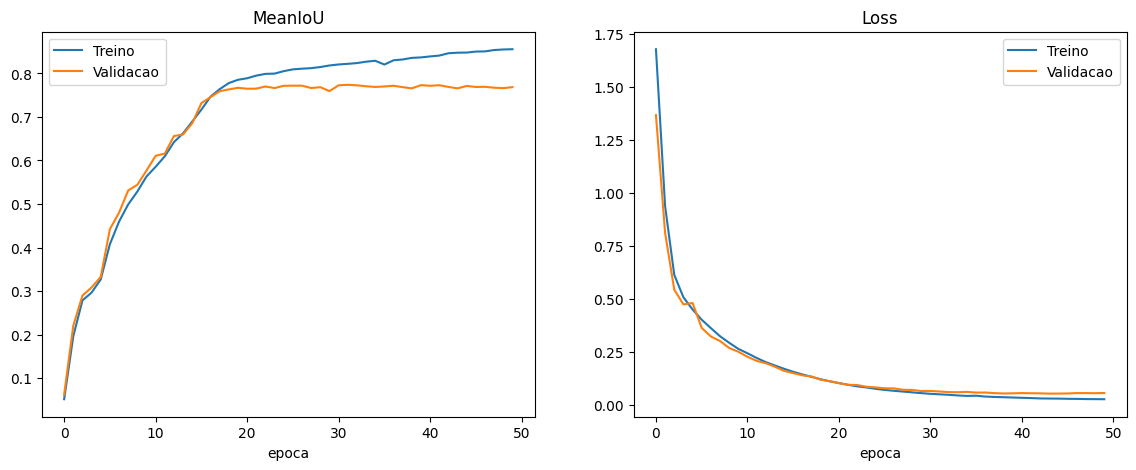

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(treino.history['mean_io_u'], label='Treino')
plt.plot(treino.history['val_mean_io_u'], label='Validacao')
plt.title('MeanIoU')
plt.xlabel('epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(treino.history['loss'], label='Treino')
plt.plot(treino.history['val_loss'], label='Validacao')
plt.title('Loss')
plt.xlabel('epoca')
plt.legend()

plt.show()
